<a href="https://colab.research.google.com/github/shuob3344/MSSP6070/blob/main/Assignments/MSSP6070_Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
from io import BytesIO
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Insert and read data
# Set the repository owner and name
owner = "shuob3344"
repository = "MSSP6070"

# Set the CSV path inside the repository
file_path = "data/data_academic_performance.csv"

# Read the GitHub token from Colab Secrets
github_token = userdata.get("git_hub")

# Request the CSV file from the private repository
url = f"https://api.github.com/repos/{owner}/{repository}/contents/{file_path}"

response = requests.get(url, headers={"Authorization": f"Bearer {github_token}", "Accept": "application/vnd.github.raw+json"}, timeout=30)

# Check whether the request was successful
response.raise_for_status()

# Load the CSV into a DataFrame
df = pd.read_csv(BytesIO(response.content))

# Check the loaded data
print("Data shape:", df.shape)
df.head()

Data shape: (12411, 45)


,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2


In [2]:
df.columns.tolist()

['COD_S11',
 'GENDER',
 'EDU_FATHER',
 'EDU_MOTHER',
 'OCC_FATHER',
 'OCC_MOTHER',
 'STRATUM',
 'SISBEN',
 'PEOPLE_HOUSE',
 'Unnamed: 9',
 'INTERNET',
 'TV',
 'COMPUTER',
 'WASHING_MCH',
 'MIC_OVEN',
 'CAR',
 'DVD',
 'FRESH',
 'PHONE',
 'MOBILE',
 'REVENUE',
 'JOB',
 'SCHOOL_NAME',
 'SCHOOL_NAT',
 'SCHOOL_TYPE',
 'MAT_S11',
 'CR_S11',
 'CC_S11',
 'BIO_S11',
 'ENG_S11',
 'Cod_SPro',
 'UNIVERSITY',
 'ACADEMIC_PROGRAM',
 'QR_PRO',
 'CR_PRO',
 'CC_PRO',
 'ENG_PRO',
 'WC_PRO',
 'FEP_PRO',
 'G_SC',
 'PERCENTILE',
 '2ND_DECILE',
 'QUARTILE',
 'SEL',
 'SEL_IHE']

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12411 entries, 0 to 12410
Data columns (total 45 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   COD_S11           12411 non-null  object 
 1   GENDER            12411 non-null  object 
 2   EDU_FATHER        12411 non-null  object 
 3   EDU_MOTHER        12411 non-null  object 
 4   OCC_FATHER        12411 non-null  object 
 5   OCC_MOTHER        12411 non-null  object 
 6   STRATUM           12411 non-null  object 
 7   SISBEN            12411 non-null  object 
 8   PEOPLE_HOUSE      12411 non-null  object 
 9   Unnamed: 9        0 non-null      float64
 10  INTERNET          12411 non-null  object 
 11  TV                12411 non-null  object 
 12  COMPUTER          12411 non-null  object 
 13  WASHING_MCH       12411 non-null  object 
 14  MIC_OVEN          12411 non-null  object 
 15  CAR               12411 non-null  object 
 16  DVD               12411 non-null  object

In [4]:
df = df.drop(columns=["Unnamed: 9"])

df.shape

(12411, 44)

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

,0
COD_S11,0
GENDER,0
EDU_FATHER,0
EDU_MOTHER,0
OCC_FATHER,0
OCC_MOTHER,0
STRATUM,0
SISBEN,0
PEOPLE_HOUSE,0
INTERNET,0


In [7]:
df.describe()

,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
count,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.00000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000
mean,64.320764,60.778422,60.705181,63.950528,61.801064,77.417291,62.199339,59.18677,67.498348,53.703408,145.476593,162.710499,68.446459,3.885747,3.188865,2.598904,2.409395
std,11.873650,10.025876,10.120524,11.156869,14.297777,22.673444,27.666558,28.99184,25.495096,30.001734,40.126386,23.112479,25.867550,1.248431,0.979043,1.111704,0.926765
min,26.000000,24.000000,0.000000,11.000000,26.000000,1.000000,1.000000,1.00000,1.000000,0.000000,1.000000,37.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,56.000000,54.000000,54.000000,56.000000,50.000000,65.000000,42.000000,36.00000,51.000000,28.000000,124.000000,147.000000,51.000000,3.000000,3.000000,2.000000,2.000000
50%,64.000000,61.000000,60.000000,64.000000,59.000000,85.000000,67.000000,65.00000,74.000000,56.000000,153.000000,163.000000,75.000000,4.000000,4.000000,2.000000,2.000000
75%,72.000000,67.000000,67.000000,71.000000,72.000000,96.000000,86.000000,85.00000,88.000000,80.000000,174.000000,179.000000,90.000000,5.000000,4.000000,4.000000,3.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,300.000000,247.000000,100.000000,5.000000,4.000000,4.000000,4.000000


In [8]:
print(df["GENDER"].value_counts())
print(df["EDU_FATHER"].value_counts())
print(df["EDU_MOTHER"].value_counts())
print(df["STRATUM"].value_counts())

GENDER
M    7368
F    5043
Name: count, dtype: int64
EDU_FATHER
Complete professional education          3016
Complete Secundary                       2843
Complete technique or technology         1194
Incomplete Secundary                     1091
Postgraduate education                   1085
Complete primary                          824
Incomplete primary                        735
Incomplete Professional Education         425
Not sure                                  407
0                                         391
Incomplete technical or technological     277
Ninguno                                   123
Name: count, dtype: int64
EDU_MOTHER
Complete Secundary                       3106
Complete professional education          3059
Complete technique or technology         1495
Incomplete Secundary                     1056
Postgraduate education                    997
Complete primary                          713
Incomplete primary                        541
Incomplete Professional E

In [9]:
father_results = df.groupby("EDU_FATHER")["G_SC"].mean().sort_values()

father_results

,G_SC
EDU_FATHER,
0,155.076726
Complete primary,155.195388
Incomplete primary,155.729252
Incomplete Secundary,156.535289
Ninguno,156.634146
Complete Secundary,158.785790
Not sure,160.294840
Incomplete technical or technological,162.101083
Complete technique or technology,164.033501


In [10]:
mother_results = df.groupby("EDU_MOTHER")["G_SC"].mean().sort_values()

mother_results

,G_SC
EDU_MOTHER,
Ninguno,149.705882
Incomplete primary,154.853974
0,154.930412
Complete primary,155.336606
Incomplete Secundary,155.672348
Complete Secundary,158.470702
Not sure,159.407821
Incomplete technical or technological,161.879765
Complete technique or technology,163.242140


In [11]:
father_difference = father_results["Postgraduate education"] - father_results["Complete professional education"]

mother_difference = mother_results["Postgraduate education"] - mother_results["Complete professional education"]

print("Father difference:", father_difference)
print("Mother difference:", mother_difference)

Father difference: 9.219338336857788
Mother difference: 6.791536426868049


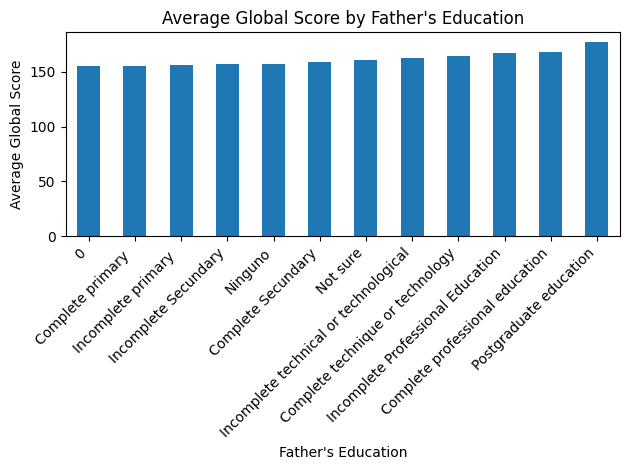

In [12]:
father_results.plot(kind="bar")

plt.title("Average Global Score by Father's Education")
plt.xlabel("Father's Education")
plt.ylabel("Average Global Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

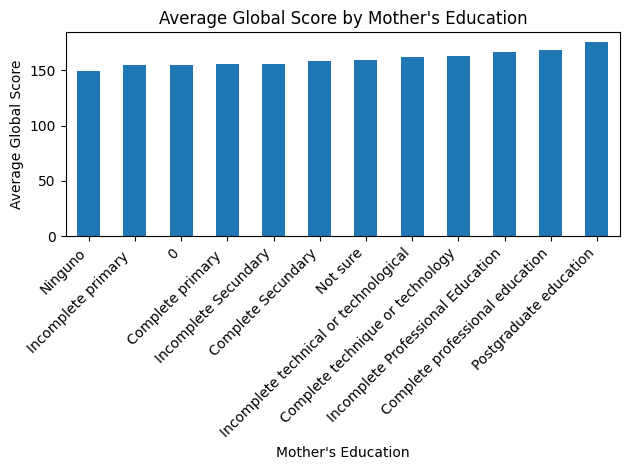

In [13]:
mother_results.plot(kind="bar")

plt.title("Average Global Score by Mother's Education")
plt.xlabel("Mother's Education")
plt.ylabel("Average Global Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [14]:
stratum_results = df.groupby("STRATUM")["G_SC"].mean().sort_values()

stratum_results

,G_SC
STRATUM,
Stratum 1,152.352838
0,154.000000
Stratum 2,158.199305
Stratum 3,163.815328
Stratum 4,172.002535
Stratum 5,177.387046
Stratum 6,181.511166


In [15]:
stratum_difference = stratum_results["Stratum 6"] - stratum_results["Stratum 1"]

print("Difference between Stratum 6 and Stratum 1:", stratum_difference)

Difference between Stratum 6 and Stratum 1: 29.15832833619126


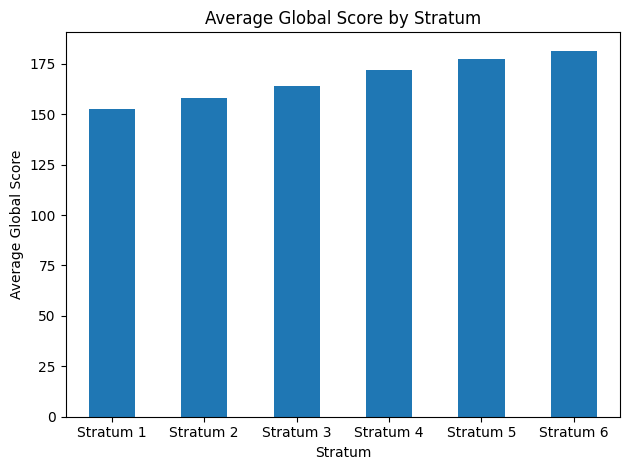

In [16]:
stratum_plot = stratum_results.drop("0")

stratum_plot.plot(kind="bar")

plt.title("Average Global Score by Stratum")
plt.xlabel("Stratum")
plt.ylabel("Average Global Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

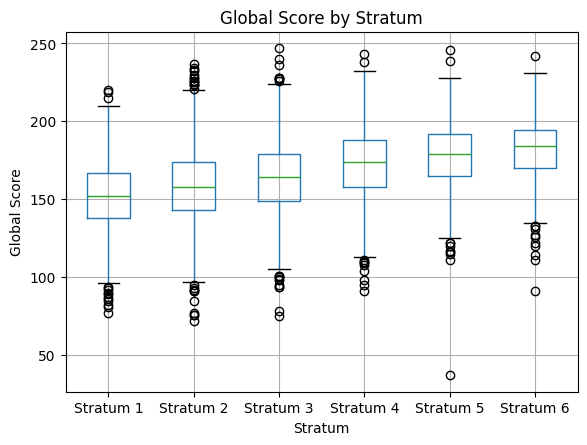

In [17]:
df[df["STRATUM"] != "0"].boxplot(column="G_SC", by="STRATUM")

plt.title("Global Score by Stratum")
plt.suptitle("")
plt.xlabel("Stratum")
plt.ylabel("Global Score")
plt.show()

In [18]:
gender_results = df.groupby("GENDER")["G_SC"].mean()

gender_results

,G_SC
GENDER,
F,161.278207
M,163.690825


In [19]:
gender_difference = gender_results["M"] - gender_results["F"]

print("Difference between male and female:", gender_difference)

Difference between male and female: 2.4126177737903447


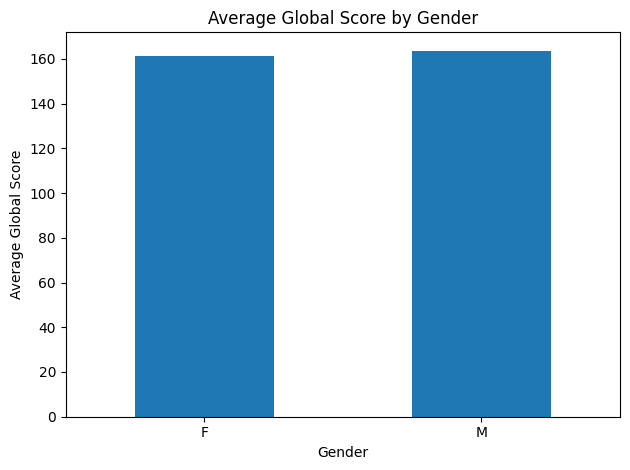

In [20]:
gender_results.plot(kind="bar")

plt.title("Average Global Score by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Global Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
pro_scores = df[["QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO", "G_SC"]]

pro_scores.corr()

,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,G_SC
QR_PRO,1.000000,0.570196,0.460823,0.503816,0.199595,0.699914
CR_PRO,0.570196,1.000000,0.607908,0.527087,0.248994,0.786409
CC_PRO,0.460823,0.607908,1.000000,0.477633,0.238128,0.757822
ENG_PRO,0.503816,0.527087,0.477633,1.000000,0.252745,0.724643
WC_PRO,0.199595,0.248994,0.238128,0.252745,1.000000,0.554962
G_SC,0.699914,0.786409,0.757822,0.724643,0.554962,1.000000


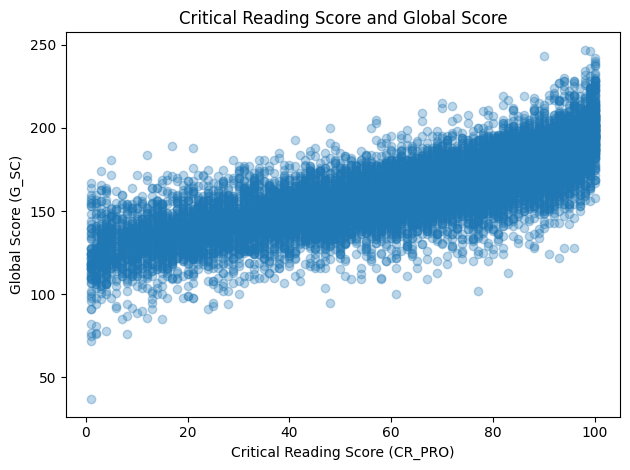

In [22]:
plt.scatter(df["CR_PRO"], df["G_SC"], alpha=0.3)

plt.title("Critical Reading Score and Global Score")
plt.xlabel("Critical Reading Score (CR_PRO)")
plt.ylabel("Global Score (G_SC)")
plt.tight_layout()
plt.show()